<a href="https://colab.research.google.com/github/rjngoh/credit-card-customer-segmentation/blob/main/credit_card_customer_segmentation_and_promotional_strategy_optimisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Credit Card Customer Segmentation and Promotional Strategy Optimisation Using K-Means Clustering, and Apriori Association Rule Mining
<font size = 2> Rayjayneil Goh (Last Updated: 24 Nov 2026)</font>

This project follows the **Cross-Industry Standard Process for Data Mining (CRISP-DM)** framework which involves six phases.

**Workflow:** Business Understanding → Data Understanding → Data Preparation → Modelling (K-Means Clustering) → Evaluation → Modelling (Apriori Association Rule Mining) → Evaluation → Deployment

### Phase 1: Business understanding

A credit card provider is losing out on potential revenue because of customers who maintain a zero balance on their credit cards.

The **business objective** is to encourage spending through targeted promotions, to increase the revenue of the company.

The **data mining objectives** are to segment customers to **identify the target group** for promotions, as sending promotional materials to all customers is not cost-effective. Additionally, the company wants to develop an effective promotional strategy by **bundling** the relevant promotional activities together for a campaign that can increase customer engagement of the targeted segments, encouraging them to make purchases using their credit cards to generate more revenue for the company.

### Setting up the notebook:

1. Download the `cardholder_campaign_data.csv` file, and upload it to the Google Colab session.
2. Install mlxtend if needed using `%pip install mlxtend`.
3. Run all cells in order.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score
#import mlxtend
from mlxtend.frequent_patterns import apriori, association_rules

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Deprecation warnings appear when we run Python code after importing the `mlxtend` library for association analysis.

This happens when there are libraries in the code that are going to evolve in future versions of IPython. It is a warning for library developers to update their extensions. As an end-user, nothing much can be done about it other than wait for the library developers to make the required changes. We can consider downgrading IPython to an older version to fix remove the warnings.

This warning does not indicate that there is anything wrong with usage of mlxtend or any other library as it is only there to serve as a notice to developers who are building tools or libraries that interact with IPython.

filterwarnings is used from the warnings library to suppress all warnings.

In [2]:
#Suppress all warnings
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Load the dataset into a DataFrame using the `pandas` **read_csv()** function, and assign this DataFrame to the variable named *df*.

**set_index( )** function used to set the index to 'Customer_ID' for easy retrieval of particular customer id(s)

The **head()** function returns the first five rows in the DataFrame for verification purposes

In [3]:
df = pd.read_csv('cardholder_campaign_data.csv')
df.set_index('Customer_ID', inplace=True)

df.head()

,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
Customer_ID,,,,,,,,,,,,
C0001,38,23357.0,Yes,No,No,No,No,Yes,No,No,No,No
C0002,32,21379.0,Yes,No,No,No,No,No,No,No,No,No
C0003,40,27831.0,No,Yes,No,No,No,No,No,Yes,No,No
C0004,48,29658.0,Yes,Yes,No,No,No,No,No,No,Yes,No
C0005,31,15414.0,No,Yes,Yes,No,No,Yes,No,Yes,Yes,No


### Phase 2: Data Understanding

This is where Data Exploration using descriptive statistics and visualisation is conducted to get insights and detect data quality issues.

In [4]:
df.describe(include='all')

,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
count,777.000000,776.000000,777,777,777,777,777,777,777,777,777,777
unique,NaN,NaN,2,2,2,2,2,2,2,2,2,3
top,NaN,NaN,No,No,No,No,No,No,No,No,No,No
freq,NaN,NaN,393,465,471,712,632,444,754,700,409,399
mean,33.920206,22703.787371,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,8.738693,5952.902537,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,15.000000,4515.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,27.000000,18724.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,34.000000,22851.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,40.000000,26764.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


The above output of summary statistics shows a count of 776 out of 777 observations for the 'Income' variable, indicating a missing value. In addition, the 'Zero-Balance_Cardholders' variable contains 3 unique categorical values, indicating a potential data quality issue as there should only be two values - **Yes** or **No**. These are flagged as potential data quality issues to be further explored.

In [5]:
df.sort_values('Age', ascending=True)

,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
Customer_ID,,,,,,,,,,,,
C0377,15,30323.0,No,No,Yes,No,No,No,No,No,No,Yes
C0482,18,15125.0,No,No,No,No,No,No,No,No,No,Yes
C0635,18,17169.0,No,No,Yes,No,No,Yes,No,No,No,Yes
C0438,18,20446.0,Yes,Yes,No,No,No,Yes,No,No,Yes,Yes
C0630,18,21609.0,Yes,Yes,No,No,No,No,No,No,Yes,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...
C0654,58,36999.0,No,Yes,Yes,No,No,Yes,No,No,No,Yes
C0755,59,35086.0,No,Yes,Yes,No,No,No,No,No,Yes,No
C0180,59,35551.0,No,Yes,Yes,No,Yes,Yes,No,No,Yes,Yes


The above output identifies Customer_ID **C0377** where Age = 15, to be erroneous as credit cards are stated to only be eligible for individuals aged 18 or above.

In [6]:
df[df.isna().any(axis=1)]

,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
Customer_ID,,,,,,,,,,,,
C0527,34,NaN,Yes,No,Yes,No,No,No,No,No,No,Yes


Customer_ID **C0527** contains a missing value in 'Income' with the value NaN (Not a Number).

The **value_counts( )** function is used to get the counts of unique values in the 'Zero-Balance_Cardholder' column.

In [7]:
df['Zero-Balance_Cardholder'].value_counts()

,count
Zero-Balance_Cardholder,
No,399
Yes,377
yes,1


The observed categorical value 'yes' in the 'Zero-Balance_Cardholder' column is determined to be erroneous, which can negatively affect the outcome of the data mining project if left uncorrected.

In [8]:
df[df['Zero-Balance_Cardholder'] == 'yes']

,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
Customer_ID,,,,,,,,,,,,
C0477,37,29051.0,No,No,Yes,Yes,No,No,No,Yes,Yes,yes


By using Boolean indexing, Customer_ID **C0477** is identified to contain the inconsistent category of 'yes'

In [9]:
#The duplicated method creates a Boolean mask, instructing Python to check every cell of the DataFrame and return True if it is a duplicate
duplicates = df.duplicated()

#Boolean indexing to identify affected rows
df[duplicates]

,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
Customer_ID,,,,,,,,,,,,
C0248,27,27089.0,Yes,No,Yes,No,No,Yes,No,No,No,Yes


In [10]:
#List of column names to check for duplication
column_names = ['Age', 'Income']

#The keep=False argument here allows us to keep all occurences of duplicate values
duplicates = df.duplicated(subset=column_names, keep=False)

df[duplicates]

,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
Customer_ID,,,,,,,,,,,,
C0248,27,27089.0,Yes,No,Yes,No,No,Yes,No,No,No,Yes
C0248,27,27089.0,Yes,No,Yes,No,No,Yes,No,No,No,Yes


There are two rows of complete duplicates for Customer_ID **C0248**.

### Phase 3: Data Preparation

This phase involves selecting the appropriate data, and preparing them for data mining. Data cleaning is performed to handle missing values, inconsistent categorical values, duplicate observations, and outliers.

Boolean indexing is used to select only rows where 'Age' is >= 18.

```
df['Age']>=18        # This is a Boolean mask
df[df['Age']>=18]    # This is Boolean indexing
```

In [11]:
df = df[df['Age']>=18]

df

,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
Customer_ID,,,,,,,,,,,,
C0001,38,23357.0,Yes,No,No,No,No,Yes,No,No,No,No
C0002,32,21379.0,Yes,No,No,No,No,No,No,No,No,No
C0003,40,27831.0,No,Yes,No,No,No,No,No,Yes,No,No
C0004,48,29658.0,Yes,Yes,No,No,No,No,No,No,Yes,No
C0005,31,15414.0,No,Yes,Yes,No,No,Yes,No,Yes,Yes,No
...,...,...,...,...,...,...,...,...,...,...,...,...
C0772,40,30434.0,No,Yes,No,No,No,No,No,No,No,No
C0773,43,26059.0,Yes,Yes,No,No,No,No,No,No,No,No
C0774,40,24090.0,Yes,Yes,No,No,Yes,No,No,No,No,No


**Handling Missing Values**

The **dropna( )** function is used to remove any row with at least one missing value (NaN).

In [12]:
df.dropna(inplace=True)

df

,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
Customer_ID,,,,,,,,,,,,
C0001,38,23357.0,Yes,No,No,No,No,Yes,No,No,No,No
C0002,32,21379.0,Yes,No,No,No,No,No,No,No,No,No
C0003,40,27831.0,No,Yes,No,No,No,No,No,Yes,No,No
C0004,48,29658.0,Yes,Yes,No,No,No,No,No,No,Yes,No
C0005,31,15414.0,No,Yes,Yes,No,No,Yes,No,Yes,Yes,No
...,...,...,...,...,...,...,...,...,...,...,...,...
C0772,40,30434.0,No,Yes,No,No,No,No,No,No,No,No
C0773,43,26059.0,Yes,Yes,No,No,No,No,No,No,No,No
C0774,40,24090.0,Yes,Yes,No,No,Yes,No,No,No,No,No


**Handling Inconsistent Entries**

The **replace( )** function is used to replace 'yes' with 'Yes', and the `inplace` parameter is set to True so that the changes are saved to the DataFrame.

The **value_counts( )** function is used to verify the treatment of the inconsistent entry.

In [13]:
df['Zero-Balance_Cardholder'].replace('yes', 'Yes', inplace=True)

df['Zero-Balance_Cardholder'].value_counts()

/tmp/ipykernel_65858/4082645126.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Zero-Balance_Cardholder'].replace('yes', 'Yes', inplace=True)


,count
Zero-Balance_Cardholder,
No,399
Yes,376


**Handling Duplicate Observations**

In [14]:
#Remove rows with duplicates
#The keep='first' argument here allows us to keep one of the duplicates while discarding the others
df.drop_duplicates(keep='first', inplace=True)

**Handling Outliers**

Outliers are observations that are unusually high or low compared to the majority of data points. They can be visualised using a boxplot, where values outside the inner fences are flagged as potential outliers

Boxplots are created for variables 'Age' and 'Income' to check for outliers using the `seaborn` library

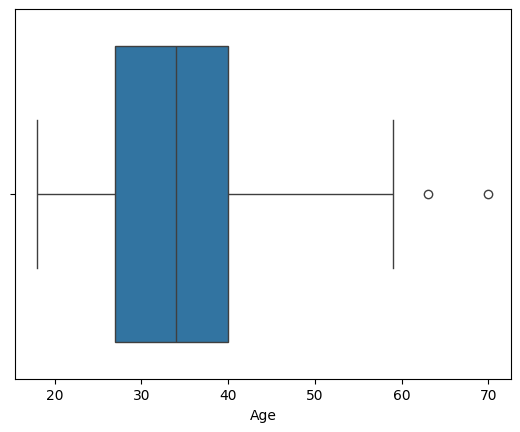

In [15]:
sns.boxplot(x='Age', data=df)

plt.show()

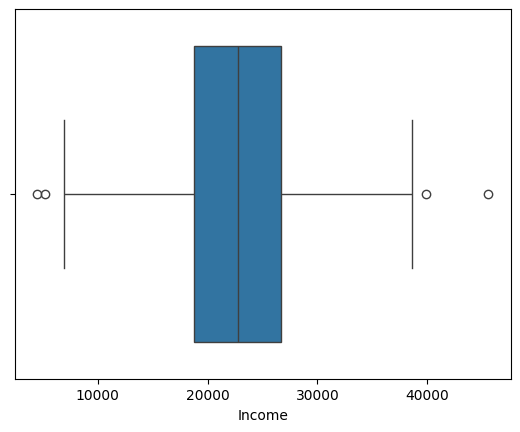

In [16]:
sns.boxplot(x='Income', data=df)

plt.show()

The observed statistical outliers in the 'Age' variable are determined to be valid observations as they are within a reasonable age range, with no extreme and unrealistic values. These values are retained as they are not considered erroneous.

The observed statistical outliers in the 'Income' variable are also determined to be valid observations. The assumption is that with age, the older a customer is, the higher their income. On the other hand, the younger the customer, the lower their income. Unless we can find a source record stating otherwise, these values are retained as they are not considered erroneous.

Although no action is required, it is still good practice to examine the outliers to ensure that they are valid observations and not data entry errors.

Boolean indexing is used to verify rows with outliers in both 'Age' and 'Income' variables.

In [17]:
Q1_age = df['Age'].quantile(0.25)
Q3_age = df['Age'].quantile(0.75)
IQR_age = Q3_age - Q1_age

lower_bound_age = Q1_age - 1.5 * IQR_age
upper_bound_age = Q3_age + 1.5 * IQR_age

age_outliers = df[(df['Age'] < lower_bound_age) | (df['Age'] > upper_bound_age)]

age_outliers

,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
Customer_ID,,,,,,,,,,,,
C0210,70,45548.0,Yes,Yes,No,No,No,Yes,No,Yes,No,No
C0478,63,30264.0,No,No,No,No,No,Yes,No,No,No,No


In [18]:
Q1_income = df['Income'].quantile(0.25)
Q3_income = df['Income'].quantile(0.75)
IQR_income = Q3_income - Q1_income

lower_bound_income = Q1_income - 1.5 * IQR_income
upper_bound_income = Q3_income + 1.5 * IQR_income

income_outliers = df[(df['Income'] < lower_bound_income) | (df['Income'] > upper_bound_income)]

income_outliers

,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
Customer_ID,,,,,,,,,,,,
C0210,70,45548.0,Yes,Yes,No,No,No,Yes,No,Yes,No,No
C0324,24,5211.0,No,No,No,No,No,No,No,No,No,No
C0578,20,4515.0,No,Yes,No,No,No,Yes,No,No,No,Yes
C0605,51,39900.0,Yes,No,No,No,No,No,No,No,Yes,No


### Modelling (K-Means Clustering) (CRISP-DM Phase 4)

This is where the K-Means model is built to segment customers for targeted promotions.

Additional data preparation such as selecting the appropriate data, and Min-Max normalisation is required before it can be applied into the K-Means algorithm.

Additionally, different values of K (number of clusters) will be tested and evaluated, based on metrics such as the average silhouette coefficient, as well as the principle of parsimony to select a final 'best model'.

It is necessary to select the appropriate data before applying algorithms.

K-Means works best with numerical columns because it uses distance measures as a metric for clustering. Therefore, numerical variables 'Age', and 'Income' are selected.

A new object, **columns_clustering** is defined as a list containing only columns 'Age', and 'Income'.

In [19]:
columns_clustering = ['Age','Income']

df_clustering = df[columns_clustering]

df_clustering.head()

,Age,Income
Customer_ID,,
C0001,38,23357.0
C0002,32,21379.0
C0003,40,27831.0
C0004,48,29658.0
C0005,31,15414.0


Plot the scatterplot of Income and Age

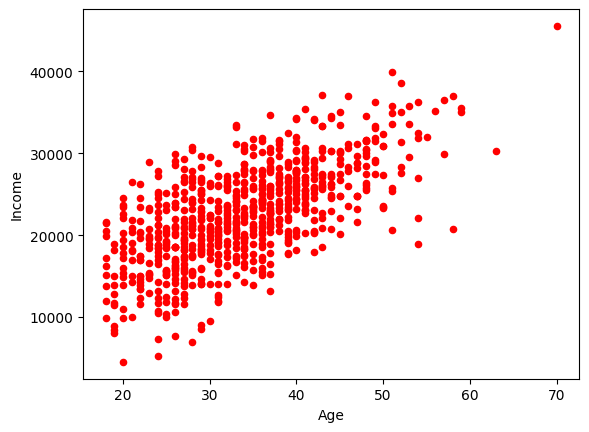

In [20]:
plt.scatter(df_clustering['Age'], df_clustering['Income'], c='red', s=20)

plt.xlabel('Age')
plt.ylabel('Income')

plt.show()

Age and income have different measurement scales, so Min-Max normalisation is applied before K-Means clustering to prevent income from disproportionately influencing Euclidean distance calculations.

**MinMaxScaler** is used to perform min-max normalisation.

First, an instance called "scaler" is created.

The **scaler.fit_transform( )** function is used to fit the scaler to the data and transform it

The output from the **scaler.fit_transform( )** function is a NumPy array.

This NumPy array is converted back to a DataFrame, using its original column names. It is common practice to convert the output of the scaler.fit_transform( ) function to a DataFrame for easier manipulation and integration with other pandas operations.

In [21]:
scaler = MinMaxScaler()

df_normalised = scaler.fit_transform(df_clustering)

df_normalised = pd.DataFrame(df_normalised, columns=df_clustering.columns)

df_normalised.head()

,Age,Income
0,0.384615,0.459191
1,0.269231,0.410986
2,0.423077,0.568226
3,0.576923,0.612751
4,0.250000,0.265615


First, a model object named 'model' is created.

There are various parameters we can adjust, such as n_clusters, and random_state. The n_clusters parameter refers to the number of clusters, **K**, in K-Means.

The random_state parameter is used to set the seed for the random number generator, ensuring that the outputs are reproducible across different runs with the same parameters. The KMeans algorithm involves the random placement of the initial cluster centroids, influencing the final output. Setting a specific value for random_state allows us to get the same result every time we run the algorithm with the same data and parameters.

In [22]:
k = 2

model = KMeans(n_clusters=k, random_state=42)

model

KMeans(n_clusters=2, random_state=42)

After creating the model object, we can fit our data into the model.

The **model.fit_predict( )** function is used to learn from the data, and assign cluster labels to the data points.

The data used in the function should be normalised as features on larger scales can influence the model.

The model.fit_predict( ) function will return a list of cluster labels for each data point in the input data. For *n_clusters*=2, these labels will be 0 or 1, indicating which cluster each data point is assigned to.

In [23]:
labels = model.fit_predict(df_normalised)

labels

array([0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1,
       1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0,
       1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0,
       1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0,
       1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1,
       0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1,
       1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0,
       0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1,
       0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1,
       0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1,

For result interpretation, we need information on the value of the centroids.

`kmeans.cluster_centers_` is used to view the centroids.

The centroids are in the normalised space as we have normalised the data before fitting KMeans. To get the centroids in the original data space, the centroids will need to be inverse transformed using the same scaler used for normalisation.

The **inverse_transform( )** function is used to convert the centroids back to the original dataset's scale.

In [24]:
normalised_centroids = model.cluster_centers_
centroids = scaler.inverse_transform(normalised_centroids)

centroids

array([[   41.25348189, 27078.61559889],
       [   27.63855422, 18890.37108434]])

A scatterplot is created to visualise the clustering solution.

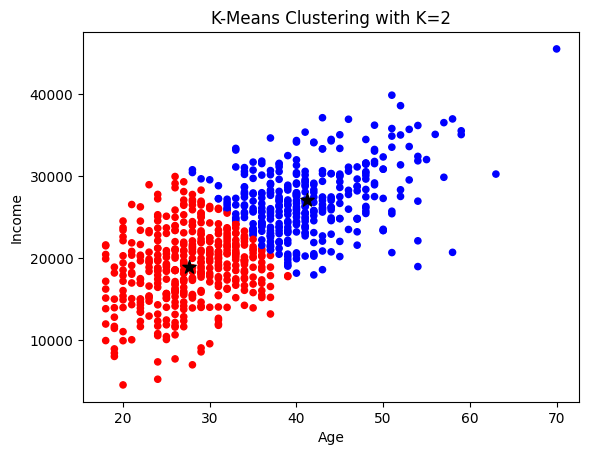

In [25]:
# Map the labels to colours
c = ['b', 'r', 'y', 'g', 'c', 'm']
colours = [c[i] for i in labels]

# Plot the scatterplot with all data points and centriods
plt.scatter(df['Age'], df['Income'], c=colours, s=20)
plt.scatter(centroids[:,0], centroids[:,1], marker='*', s=100, c='black')

# Add a title and labels
plt.title('K-Means Clustering with K=2')
plt.xlabel('Age')
plt.ylabel('Income')

#Display the plot
plt.show()

The **silhouette_score** function from the metrics module is used to calculate the average silhouette coefficient of all customers in the dataset.

In [26]:
silhouette_score(df_normalised, labels)

np.float64(0.4544859485824965)

Before deciding on the optimal K-value for the clustering solution, different values of K from 2 to 6 is tested, and the optimal K is the one that yields the highest average Silhouette Coefficient.

In [27]:
for k in range (2, 7):
    kmeans = KMeans(n_clusters=k, random_state=42)

    kmeans = kmeans.fit(df_normalised)

    print(f'Average Silhouette coefficient for k={k}: {silhouette_score(df_normalised, kmeans.labels_)}')

Average Silhouette coefficient for k=2: 0.4544859485824965
Average Silhouette coefficient for k=3: 0.36644779688865553
Average Silhouette coefficient for k=4: 0.3250023551837589
Average Silhouette coefficient for k=5: 0.3532778211134028
Average Silhouette coefficient for k=6: 0.33649137554717723


From the calculation, K=2 seems to be the optimal K-value, achieving the highest average silhouette coefficient and is therefore used in subsequent iterations to get the final 'best model'.

**Model Evaluation & Selection**

The above clustering solution has already been determined to be the 'best model' after running a total of 3 iterations.

For the first iteration, a K-value of 3 was used. This resulted in a Silhouette score of approximately 0.37. Only after the first iteration were we able to find the optimal K, K=2, by testing different values of K from 2 to 6. After the first iteration, K=2 was used in subsequent iterations.

Outlier sensitivity testing was performed in the second and third iterations.

In the second iteration, a K-value of 2 was used, and 'Age' and 'Income' outliers were retained to perform K-Means clustering. This iteration resulted in a Silhouette score of approximately 0.45.

In the third iteration, a K-value of 2 was used, but outliers were removed before performing K-Means clustering, as K-means is sensitive to outliers and a small number of data can substantially influence the result. The resulting Silhouette score is approximately 0.45, where the difference between this iteration and the second is negligible.

Since there are no noticeable improvements by removing outliers, the second iteration was selected as the 'best model', retaining the outliers (which was previously already assessed to be valid rather than erroneous).

### Evaluation (K-Means Clustering) (CRISP-DM Phase 5)

To assess whether the Clustering solution is meaningful and useful from a business perspective, the proportion of zero-balance cardholders will be computed to identify the target for promotions.

A new column named 'Cluster' in the df_clustering DataFrame is created where the values are taken from labels, which contains the cluster assignments(e.g., 0,1) that were generated by the K-Means clustering algorithm for each data point.

In [28]:
df_clustering['Cluster'] = labels

df_clustering.head()

/tmp/ipykernel_65858/3747550148.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clustering['Cluster'] = labels


,Age,Income,Cluster
Customer_ID,,,
C0001,38,23357.0,0
C0002,32,21379.0,1
C0003,40,27831.0,0
C0004,48,29658.0,0
C0005,31,15414.0,1


The two resulting clusters generated from the clustering solution is therefore categorised as **'Younger, Lower Income'**, and **'Older, Higher Income'**.

The cluster labels in the DataFrame are renamed for easier understanding.

In [29]:
df_clustering['Cluster'].replace(0, 'Older, Higher Income', inplace=True)
df_clustering['Cluster'].replace(1, 'Younger, Lower Income', inplace=True)

df_clustering.head()

/tmp/ipykernel_65858/458623128.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_clustering['Cluster'].replace(0, 'Older, Higher Income', inplace=True)
/tmp/ipykernel_65858/458623128.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clustering['Cluster'].replace(0, 'Older, Higher Income', inplace=True)
/tmp/ipykernel_65858/458623128.

,Age,Income,Cluster
Customer_ID,,,
C0001,38,23357.0,"Older, Higher Income"
C0002,32,21379.0,"Younger, Lower Income"
C0003,40,27831.0,"Older, Higher Income"
C0004,48,29658.0,"Older, Higher Income"
C0005,31,15414.0,"Younger, Lower Income"


To determine whether the Clustering solution is meaningful and useful from a business perspective, the proportion of zero-balance cardholders will be computed for each cluster.

The cluster with a larger proportion of zero-balance cardholders will be identified as the target for promotions.

In [30]:
df_clustering.join(df['Zero-Balance_Cardholder'])[df['Zero-Balance_Cardholder'] == 'Yes']['Cluster'].value_counts(normalize=True) * 100

,proportion
Cluster,
"Younger, Lower Income",75.2
"Older, Higher Income",24.8


The analysis reveals that 75.2% of zero-balance cardholders are from the younger/lower-income cluster which is significantly larger than the older/higher-income cluster where the remaining 24.8% of zero-balance cardholders are from. Therefore, the **'Younger, Lower Income'** cluster is the proposed target group for promotional campaigns.

### Modelling (Apriori Association Rule Mining) (CRISP-DM Phase 4)

This is where the Apriori algorithm is used, to generate strong association rules to help the company develop effective promotional strategies.

Additional data preparation to select and convert the relevant data into Boolean is required before it can be applied into the Apriori algorithm.

The appropriate **minimum support**, and **minimum confidence** thresholds are evaluated to generate strong rules, where meaningful business insights can be derived from (there should not be too many rules).

A new object columns_association is defined as a list containing only columns that are relevant for association analysis.

These columns are variables which were excluded from the cluster analysis, so it is joined with the clustering solution for continuity.

In [31]:
#Select only columns that are relevant for association analysis
columns_association = ['Home_Appliances','Fitness_Gadgets','Dining_Vouchers','Travel_Packages','Insurance_Plans','Electronics','Entertainment','Beauty_Wellness','Groceries']

#Combines the df_clustering DataFrame which has the cluster assignments with the df_zerobalance DataFrame
df_clustered = df_clustering.join(df[columns_association])

df_clustered.head()

,Age,Income,Cluster,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries
Customer_ID,,,,,,,,,,,,
C0001,38,23357.0,"Older, Higher Income",Yes,No,No,No,No,Yes,No,No,No
C0002,32,21379.0,"Younger, Lower Income",Yes,No,No,No,No,No,No,No,No
C0003,40,27831.0,"Older, Higher Income",No,Yes,No,No,No,No,No,Yes,No
C0004,48,29658.0,"Older, Higher Income",Yes,Yes,No,No,No,No,No,No,Yes
C0005,31,15414.0,"Younger, Lower Income",No,Yes,Yes,No,No,Yes,No,Yes,Yes


Boolean indexing is used to only include observations where customers are from the 'Younger, Lower Income cluster' in the DataFrame, which is the targeted segment for association analysis.

In [32]:
df_clustered = df_clustered[df_clustered['Cluster'] == 'Younger, Lower Income']

df_clustered.head()

,Age,Income,Cluster,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries
Customer_ID,,,,,,,,,,,,
C0002,32,21379.0,"Younger, Lower Income",Yes,No,No,No,No,No,No,No,No
C0005,31,15414.0,"Younger, Lower Income",No,Yes,Yes,No,No,Yes,No,Yes,Yes
C0006,31,22967.0,"Younger, Lower Income",Yes,No,No,No,No,No,No,No,No
C0009,29,25035.0,"Younger, Lower Income",No,Yes,No,No,No,No,No,No,No
C0011,29,22325.0,"Younger, Lower Income",Yes,No,No,No,No,Yes,No,Yes,Yes


The DataFrame is subset to only include the relevant columns for association analysis.

In [33]:
#Select only columns that are relevant for association analysis
df_association = df_clustered[columns_association]

df_association.head()

,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries
Customer_ID,,,,,,,,,
C0002,Yes,No,No,No,No,No,No,No,No
C0005,No,Yes,Yes,No,No,Yes,No,Yes,Yes
C0006,Yes,No,No,No,No,No,No,No,No
C0009,No,Yes,No,No,No,No,No,No,No
C0011,Yes,No,No,No,No,Yes,No,Yes,Yes


The apriori function from the `mlxtend` library only works on DataFrame that contains `bool data`, that is either **True** or **False**. These Boolean values correspond to whether an observation in the DataFrame engaged in particular promotional activities in the past. True indicates that the customer has engaged in a particular activity before, and False implies that the customer did not engage in a particular activity.

The data types of each column in the DataFrame are verified using the dtypes property.

In [34]:
df_association.dtypes

,0
Home_Appliances,object
Fitness_Gadgets,object
Dining_Vouchers,object
Travel_Packages,object
Insurance_Plans,object
Electronics,object
Entertainment,object
Beauty_Wellness,object
Groceries,object


The columns have the type object, instead of Bool so the **map( )** function in pandas is used to substitute 'Yes' and 'No to Boolean values of True and False respectively

A **for loop** is used to iterate over all columns

In [35]:
for col in df_association.columns:
    df_association[col] = df_association[col].map({'Yes':True, 'No': False})

df_association.head()

/tmp/ipykernel_65858/2304414118.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_association[col] = df_association[col].map({'Yes':True, 'No': False})
/tmp/ipykernel_65858/2304414118.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_association[col] = df_association[col].map({'Yes':True, 'No': False})
/tmp/ipykernel_65858/2304414118.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the cav

,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries
Customer_ID,,,,,,,,,
C0002,True,False,False,False,False,False,False,False,False
C0005,False,True,True,False,False,True,False,True,True
C0006,True,False,False,False,False,False,False,False,False
C0009,False,True,False,False,False,False,False,False,False
C0011,True,False,False,False,False,True,False,True,True


In Python, Boolean is a sub-type of integers, and True is equivalent to 1 and False is equivalent to 0 when used in arithmetic operations.

The count of the number of True values in a Boolean DataFrame can be computed by simply using the **sum( )** function.

In [36]:
df_association.sum()

,0
Home_Appliances,213
Fitness_Gadgets,158
Dining_Vouchers,158
Travel_Packages,31
Insurance_Plans,75
Electronics,181
Entertainment,11
Beauty_Wellness,39
Groceries,191


A Bar chart of customer engagement frequency of promotional campaigns in the past can be plotted to help determine the appropriate **minimum Support** value of the Apriori algorithm.

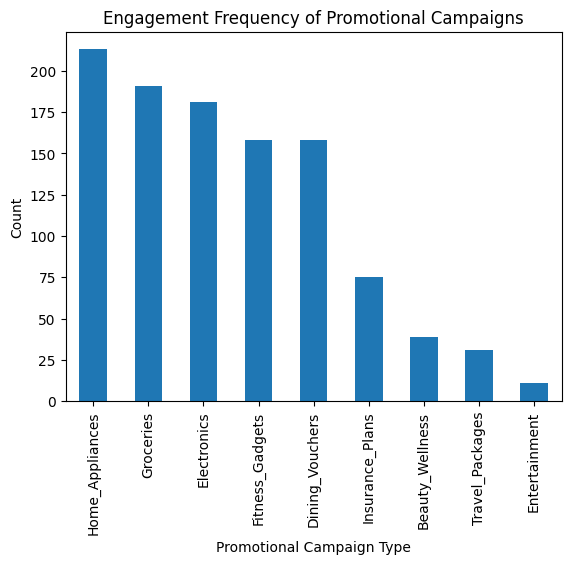

In [37]:
# Plot the bar chart
df_association.sum().sort_values(ascending=False).plot(kind='bar')

# Add a title and labels
plt.title('Engagement Frequency of Promotional Campaigns')
plt.xlabel('Promotional Campaign Type')
plt.ylabel('Count')


# Display the plot
plt.show()

As promotional campaigns take a substantial investment from businesses, it is important to decide on effective marketing strategies that are likely to yield positive returns. If the company decides to invest in promotional campaigns to include promotional activities such as Travel Packages, Beauty and Wellness, and Entertainment, the return on investment (ROI) from the campaign may not be satisfactory due to potential low turnout rates for including these activities. Therefore, a **minimum Support value of 0.1** (10%) is selected to filter out infrequent promotional activities.

The first stage in Apriori Association Rule Mining involves generating frequent itemsets.

The **apriori** function is used with a specified minimum Support, **0.1** (10%) in this case to find frequent itemsets.

The **sort_values** function is used alongside the apriori function, to sort the 'Support' column in Descending order

In [38]:
# Perform the Apriori algorithm and find frequent itemsets
frequent_itemsets = apriori(df=df_association, min_support = 0.1, use_colnames=True).sort_values('support', ascending=False)

# Display the frequent itemsets
frequent_itemsets

,support,itemsets
0,0.510791,(Home_Appliances)
5,0.458034,(Groceries)
4,0.434053,(Electronics)
2,0.378897,(Dining_Vouchers)
1,0.378897,(Fitness_Gadgets)
9,0.273381,"(Home_Appliances, Electronics)"
10,0.251799,"(Home_Appliances, Groceries)"
19,0.232614,"(Groceries, Electronics)"
6,0.223022,"(Fitness_Gadgets, Home_Appliances)"
11,0.220624,"(Fitness_Gadgets, Dining_Vouchers)"


Stage 2 in Apriori Association Rule Mining involves generating strong association rules.

The **association_rules** function is used with a specified **metric**, and minimum threshold value (in this case, the **minimum Confidence**) to generate strong association rules.

The min_threshold is adjusted based depending on specific use cases.

**Evaluating minimum Confidence threshold levels:**

Three different minimum confidence threshold values was tested to determine the best one for the business context.

In the first trial, a minimum confidence threshold of 0.6 (60%) was used, which generated a large number of interesting rules, making it difficult to derive any meaningful business insights from it.

In the second trial, a minimum confidence threshold of 0.9 (90%) was used, where no interesting rules were generated as the threshold may be too high.

In the third trial, a minimum confidence threshold of **0.8** (80%) was used, which generated a total of 3 interesting rules. This minimum confidence threshold of 80% is optimal as actionable, meaningful business insights can be derived from the generated rules.

In [39]:
# Generate association rules from the frequent itemsets
rules = association_rules(df=frequent_itemsets, metric='confidence', min_threshold=0.8).sort_values('confidence', ascending=False)

# Display the generated association rules

#Display the rules
rules

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
1,"(Insurance_Plans, Electronics)",(Home_Appliances),0.131894,0.510791,0.110312,0.836364,1.637388,1.0,0.042941,2.989608,0.448415,0.207207,0.665508,0.526163
0,"(Home_Appliances, Insurance_Plans)",(Electronics),0.134293,0.434053,0.110312,0.821429,1.892463,1.0,0.052022,3.169305,0.544743,0.240838,0.684473,0.537786
2,"(Fitness_Gadgets, Dining_Vouchers, Electronics)",(Home_Appliances),0.134293,0.510791,0.107914,0.803571,1.573189,1.0,0.039318,2.490517,0.420868,0.200893,0.598477,0.507420


One notable association identified was:

**{Insurance Plans, Electronics} → {Home Appliances} (rule support: 11%, confidence: 83.6%)**

### Evaluation (Apriori Association Rule Mining) (CRISP-DM Phase 5)

To assess whether the generated strong rules are meaningful and useful from a business perspective, they must be actionable and can help the company to develop effective promotional strategies.

The analysis produced a notable association rule – **{Insurance Plans, Electronics} → {Home Appliances}** – which indicates that approximately 83.6% of the observations involving both insurance plan and electronics promotional activities also involved home appliances promotional activity. The association provides a basis for exploring complementary promotional offerings.

### Phase 6: Deployment

This phase involves integrating the Clustering solution, and the generated strong rules into business processes.

**K-Means Clustering**: Future customers can be assigned to clusters, and those belonging to targeted segments can be flagged for personalized marketing efforts.

**Apriori Association Rule Mining**: Based on the strong rules generated, the company can develop effective promotional strategies, such as bundling the appropriate promotional activities together for the campaign, to increase customer engagement of the targeted segments.

Model performance for both should be monitored over time to maintain their benefits.

### Business Recommendations

Based on the findings, the project proposed a targeted promotional strategy involving partnerships with insurance, electronics, and home appliance providers to organize a technology-focused promotional campaign featuring credit card-linked discounts, cashback after a qualifying purchase, or reward points for a first or repeat card transaction. The proposed strategy aims to encourage card usage among targeted customer segments, while reducing unnecessary marketing expenditure.